# 📘 Cell 1 — imports & 경로 설정

In [115]:
import os
import json
import glob
from collections import Counter, defaultdict
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

# 한글 폰트 (Windows)
plt.rcParams['font.family'] = 'Malgun Gothic'
plt.rcParams['axes.unicode_minus'] = False

# 경로 (노트북이 eda/ 폴더에 있음)
ROOT = Path('..').resolve()
IMG_DIR = ROOT / 'data' / 'train_images'
TEST_DIR = ROOT / 'data' / 'test_images'
ANN_ROOT = ROOT / 'data' / 'train_annotations'

print('ROOT     :', ROOT)
print('IMG_DIR  :', IMG_DIR, '| exists:', IMG_DIR.exists())
print('TEST_DIR :', TEST_DIR, '| exists:', TEST_DIR.exists())
print('ANN_ROOT :', ANN_ROOT, '| exists:', ANN_ROOT.exists())

ROOT     : D:\pill_detection
IMG_DIR  : D:\pill_detection\data\train_images | exists: True
TEST_DIR : D:\pill_detection\data\test_images | exists: True
ANN_ROOT : D:\pill_detection\data\train_annotations | exists: True


In [116]:
# ===== Cell 1-2: 툴킷 import =====
import sys
from pathlib import Path

TOOLKIT_PATH = (Path.cwd().parent / '_toolkit').resolve()
if not TOOLKIT_PATH.exists():
    TOOLKIT_PATH = (Path.cwd() / '_toolkit').resolve()

sys.path.insert(0, str(TOOLKIT_PATH))

from utils.detection_utils import (
    check_image_file_match,
    check_orphan_references,
    bbox_sanity,
    bbox_position_stats,
    class_mismatch,
    metadata_class_bias,
)
from utils.eda_common import detect_duplicates, quick_audit, null_report

print(f'툴킷 경로: {TOOLKIT_PATH}')
print(f'경로 유효: {TOOLKIT_PATH.exists()}')

툴킷 경로: D:\pill_detection\_toolkit
경로 유효: True


# 📘 Cell 2 — 어노테이션 JSON 전부 로딩해서 DataFrame 만들기

In [89]:
# 모든 어노테이션 JSON을 1행 = 1박스 형태의 DataFrame으로 정리
json_files = glob.glob(str(ANN_ROOT / '*' / '*' / '*.json'))
print('JSON 파일 수:', len(json_files))

rows = []
for jf in json_files:
    with open(jf, 'r', encoding='utf-8') as f:
        d = json.load(f)
    img = d['images'][0]
    for ann in d['annotations']:
        x, y, w, h = ann['bbox']
        rows.append({
            'json_path': os.path.relpath(jf, ROOT),
            'file_name': img['file_name'],
            'img_w': img['width'],
            'img_h': img['height'],
            'category_id': ann['category_id'],
            'category_name': d['categories'][0]['name'],
            'drug_N': img['drug_N'],
            'drug_shape': img.get('drug_shape', ''),
            'color_class1': img.get('color_class1', ''),
            'bbox_x': x, 'bbox_y': y, 'bbox_w': w, 'bbox_h': h,
            'area_meta': ann['area'],
            'area_calc': w * h,
        })

df = pd.DataFrame(rows)
class_name_map = dict(zip(df['category_id'], df['category_name']))
print('총 박스 수(행 수):', len(df))
df.head()


JSON 파일 수: 763
총 박스 수(행 수): 763


,json_path,file_name,img_w,img_h,category_id,category_name,drug_N,drug_shape,color_class1,bbox_x,bbox_y,bbox_w,bbox_h,area_meta,area_calc
0,data\train_annotations\K-001900-016548-019607-...,K-001900-016548-019607-029451_0_2_0_2_70_000_2...,976,1280,1900,보령부스파정 5mg,K-001900,장방형,하양,644,845,189,190,35910,35910
1,data\train_annotations\K-001900-016548-019607-...,K-001900-016548-019607-029451_0_2_0_2_75_000_2...,976,1280,1900,보령부스파정 5mg,K-001900,장방형,하양,148,241,181,181,32761,32761
2,data\train_annotations\K-001900-016548-019607-...,K-001900-016548-019607-029451_0_2_0_2_90_000_2...,976,1280,1900,보령부스파정 5mg,K-001900,장방형,하양,167,248,184,182,33488,33488
3,data\train_annotations\K-001900-016548-019607-...,K-001900-016548-019607-029451_0_2_0_2_70_000_2...,976,1280,16548,가바토파정 100mg,K-016548,None,None,144,799,239,239,57121,57121
4,data\train_annotations\K-001900-016548-019607-...,K-001900-016548-019607-029451_0_2_0_2_75_000_2...,976,1280,16548,가바토파정 100mg,K-016548,None,None,578,222,233,226,52658,52658


# 📘 Cell 3 — 기본 통계 한눈에

총 이미지 수: 232
총 클래스 수: 56
총 어노테이션 수: 763
이미지 해상도 (고유): [(976, 1280)]

이미지당 박스 수 통계:
  평균: 3.29
  최소: 2
  최대: 4
  분포: {2: 7, 3: 151, 4: 74}


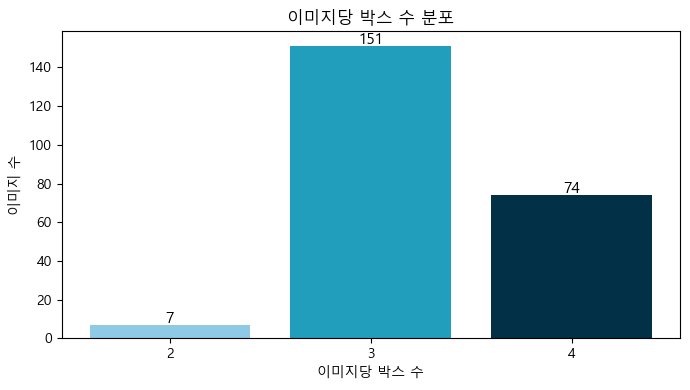

In [90]:
# ===== Cell 3: 기본 통계 + 이미지당 박스 수 시각화 =====
import matplotlib.pyplot as plt

plt.rcParams['font.family'] = 'Malgun Gothic'
plt.rcParams['axes.unicode_minus'] = False

n_imgs = df['file_name'].nunique()
n_classes = df['category_id'].nunique()
print(f"총 이미지 수: {n_imgs}")
print(f"총 클래스 수: {n_classes}")
print(f"총 어노테이션 수: {len(df)}")
print(f"이미지 해상도 (고유): {sorted(df[['img_w','img_h']].drop_duplicates().apply(tuple, axis=1).tolist())}")

boxes_per_img = df.groupby('file_name').size()
print(f"\n이미지당 박스 수 통계:")
print(f"  평균: {boxes_per_img.mean():.2f}")
print(f"  최소: {boxes_per_img.min()}")
print(f"  최대: {boxes_per_img.max()}")
print(f"  분포: {dict(boxes_per_img.value_counts().sort_index())}")

# 시각화
counts = boxes_per_img.value_counts().sort_index()
fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(counts.index.astype(str), counts.values,
              color=['#8ecae6', '#219ebc', '#023047'])
for b, v in zip(bars, counts.values):
    ax.text(b.get_x() + b.get_width()/2, v + 1, str(v),
            ha='center', fontsize=11)
ax.set_xlabel('이미지당 박스 수')
ax.set_ylabel('이미지 수')
ax.set_title('이미지당 박스 수 분포')
plt.tight_layout()
plt.show()

### 인사이트 (Cell 3)

- 전체 **232장 / 56 클래스 / 763 어노테이션** → 이미지당 평균 3.29개
- **3개 박스 이미지가 151장**으로 가장 많음 (약 65%)
- 해상도는 **976×1280 단일** → 전처리 일관성 확보
- 과제 조건 "이미지당 최대 4개" 위반 없음

# 📘 Cell 4 — 클래스별 샘플 수 분포 (불균형 확인)

클래스 개수: 56
최다: 일양하이트린정 2mg (153건)
최소: 라비에트정 20mg (3건)
중앙값: 9, 평균: 13.6
불균형 비율 (max/min): 51.0배


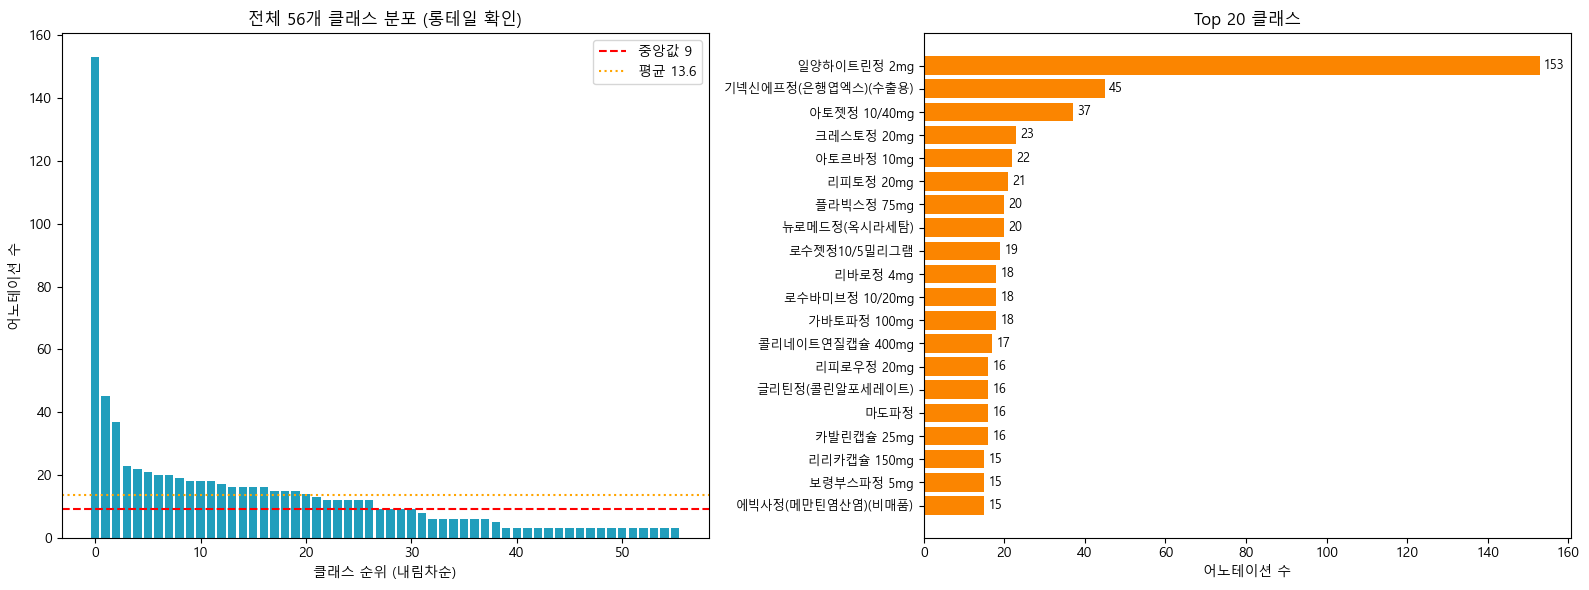


하위 10 클래스:
 category_id     category_name  n
       12247       아빌리파이정 10mg  3
       29451              레일라정  3
       27993       졸로푸트정 100mg  3
       27926         울트라셋이알서방정  3
       24850          놀텍정 10mg  3
       22362     맥시부펜이알정 300mg  3
       13395 써스펜8시간이알서방정 650mg  3
       16551     동아가바펜틴정 800mg  3
       19552      트루비타정 60mg/병  3
       21771        라비에트정 20mg  3


In [91]:
# ===== Cell 4: 클래스 불균형 분석 =====
cls_counts = (df.groupby(['category_id', 'category_name'])
                .size().reset_index(name='n')
                .sort_values('n', ascending=False)
                .reset_index(drop=True))

print(f"클래스 개수: {len(cls_counts)}")
print(f"최다: {cls_counts.iloc[0]['category_name']} ({cls_counts.iloc[0]['n']}건)")
print(f"최소: {cls_counts.iloc[-1]['category_name']} ({cls_counts.iloc[-1]['n']}건)")
print(f"중앙값: {cls_counts['n'].median():.0f}, 평균: {cls_counts['n'].mean():.1f}")
print(f"불균형 비율 (max/min): {cls_counts['n'].max() / cls_counts['n'].min():.1f}배")

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# 왼쪽: 전체 분포 (내림차순)
axes[0].bar(range(len(cls_counts)), cls_counts['n'], color='#219ebc')
axes[0].axhline(cls_counts['n'].median(), color='red', linestyle='--',
                label=f"중앙값 {cls_counts['n'].median():.0f}")
axes[0].axhline(cls_counts['n'].mean(), color='orange', linestyle=':',
                label=f"평균 {cls_counts['n'].mean():.1f}")
axes[0].set_xlabel('클래스 순위 (내림차순)')
axes[0].set_ylabel('어노테이션 수')
axes[0].set_title(f'전체 {len(cls_counts)}개 클래스 분포 (롱테일 확인)')
axes[0].legend()

# 오른쪽: Top20 수평바
top20 = cls_counts.head(20)
axes[1].barh(range(len(top20)), top20['n'], color='#fb8500')
axes[1].set_yticks(range(len(top20)))
axes[1].set_yticklabels(top20['category_name'], fontsize=9)
axes[1].invert_yaxis()
axes[1].set_xlabel('어노테이션 수')
axes[1].set_title('Top 20 클래스')
for i, v in enumerate(top20['n']):
    axes[1].text(v + 1, i, str(v), va='center', fontsize=9)

plt.tight_layout()
plt.show()

print("\n하위 10 클래스:")
print(cls_counts.tail(10).to_string(index=False))

### 인사이트 (Cell 4)

- **극심한 클래스 불균형**: max 153 vs min 3 → **약 51배 차이**
- 중앙값 9, 평균 13.6 → 전형적인 **롱테일 분포**
- 상위 20개 클래스가 전체 어노테이션의 큰 비중 차지
- **대응 전략 후보**: oversampling / class weight / focal loss / Albumentations 증강
- 하위 클래스는 3~5건 수준이라 단순 80:20 split 시 **val에 아예 안 들어갈 위험** → stratified split 필요

# 📘 Cell 5 — bbox 크기 분포 (검출 난이도 파악)

=== bbox 너비/높이/면적 통계 ===
        bbox_w   bbox_h   bbox_area  aspect_ratio  rel_area
count  763.000  763.000     763.000       763.000   763.000
mean   250.008  265.764   70384.793         0.992     0.056
std     73.772   95.653   42608.637         0.269     0.034
min    125.000  126.000   23250.000         0.396     0.019
25%    189.500  191.000   36672.000         0.829     0.029
50%    230.000  227.000   53600.000         1.000     0.043
75%    285.000  316.000   93492.500         1.041     0.075
max    529.000  664.000  272435.000         2.108     0.218


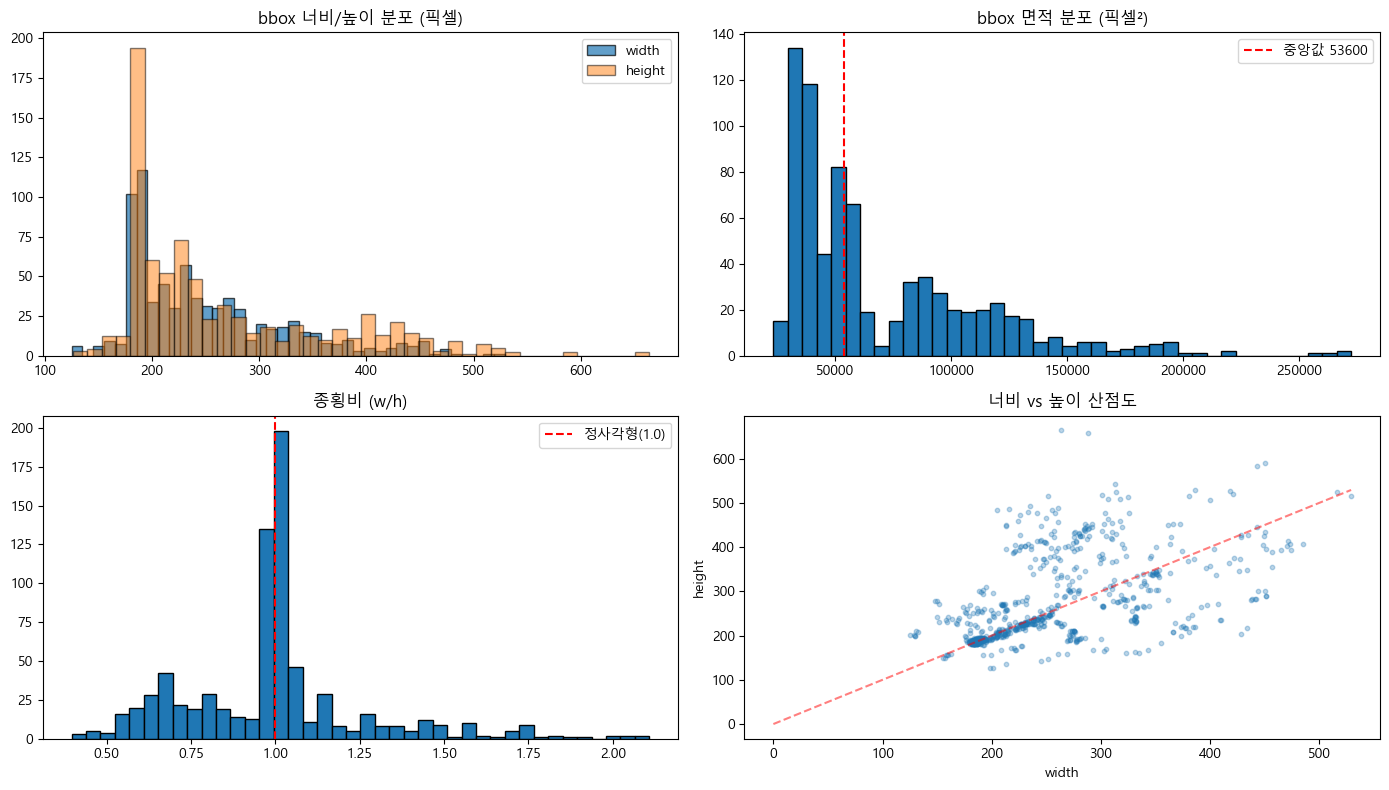

In [92]:
# bbox 크기 파생 컬럼
df['bbox_area'] = df['bbox_w'] * df['bbox_h']
df['aspect_ratio'] = df['bbox_w'] / df['bbox_h']
df['rel_area'] = df['bbox_area'] / (df['img_w'] * df['img_h'])  # 이미지 대비 박스 비율

print('=== bbox 너비/높이/면적 통계 ===')
print(df[['bbox_w', 'bbox_h', 'bbox_area', 'aspect_ratio', 'rel_area']].describe().round(3))

fig, axes = plt.subplots(2, 2, figsize=(14, 8))

axes[0, 0].hist(df['bbox_w'], bins=40, edgecolor='black', alpha=0.7, label='width')
axes[0, 0].hist(df['bbox_h'], bins=40, edgecolor='black', alpha=0.5, label='height')
axes[0, 0].set_title('bbox 너비/높이 분포 (픽셀)')
axes[0, 0].legend()

axes[0, 1].hist(df['bbox_area'], bins=40, edgecolor='black')
axes[0, 1].set_title('bbox 면적 분포 (픽셀²)')
axes[0, 1].axvline(df['bbox_area'].median(), color='r', linestyle='--', label=f'중앙값 {int(df["bbox_area"].median())}')
axes[0, 1].legend()

axes[1, 0].hist(df['aspect_ratio'], bins=40, edgecolor='black')
axes[1, 0].set_title('종횡비 (w/h)')
axes[1, 0].axvline(1.0, color='r', linestyle='--', label='정사각형(1.0)')
axes[1, 0].legend()

axes[1, 1].scatter(df['bbox_w'], df['bbox_h'], alpha=0.3, s=10)
axes[1, 1].set_xlabel('width'); axes[1, 1].set_ylabel('height')
axes[1, 1].set_title('너비 vs 높이 산점도')
axes[1, 1].plot([0, df['bbox_w'].max()], [0, df['bbox_w'].max()], 'r--', alpha=0.5)

plt.tight_layout()
plt.show()

### 인사이트 (Cell 5)

- **크기**: w/h 중앙값 230/227 px, max 529/664 px → 이미지(976×1280) 대비 평균 5.6%, 최대 21.8%
- **aspect ratio**: 중앙값 1.0, peak 매우 뾰족 → 알약 대부분 **위에서 본 원형/정사각 형태**
- **면적 범위**: 23k ~ 272k px² (약 12배 차) → COCO 기준 **전부 large object** (> 96² = 9216)
- **small object 문제 없음** → anchor 크기 튜닝보다 **클래스 불균형**이 더 큰 리스크
- aspect 극단치 (0.4 / 2.1)는 누운 자세·타원형 알약 → **회전/affine 증강 설계 시 참고**
- 산점도 y=x 근처 밀집 + 흩어짐 공존 → 동일 알약도 **촬영 각도에 따라 크기 편차 존재**

# 📘 Cell 6 — 이상 데이터 탐지 (범위초과 / 중복bbox / area 불일치)

In [93]:
# 6-1. bbox가 이미지 범위를 벗어나는 경우
out_of_range = df[
    (df['bbox_x'] < 0) | (df['bbox_y'] < 0) |
    (df['bbox_x'] + df['bbox_w'] > df['img_w']) |
    (df['bbox_y'] + df['bbox_h'] > df['img_h'])
]
print(f'[A] bbox가 이미지 범위 벗어남: {len(out_of_range)}건')
if len(out_of_range) > 0:
    print(out_of_range[['file_name','category_id','bbox_x','bbox_y','bbox_w','bbox_h']].to_string())

# 6-2. area 메타필드 vs w*h 불일치
area_mismatch = df[(df['area_meta'] - df['area_calc']).abs() > 1]
print(f'\n[B] area 메타 ≠ w*h: {len(area_mismatch)}건')
if len(area_mismatch) > 0:
    print(area_mismatch[['file_name','category_id','bbox_w','bbox_h','area_meta','area_calc']].to_string())

# 6-3. 같은 이미지에서 동일한 bbox 좌표가 서로 다른 클래스로 중복
dup_bbox = df.groupby(['file_name','bbox_x','bbox_y','bbox_w','bbox_h']).size().reset_index(name='n')
dup_bbox = dup_bbox[dup_bbox['n'] > 1]
print(f'\n[C] 동일 좌표 bbox 중복: {len(dup_bbox)}건')
if len(dup_bbox) > 0:
    for _, row in dup_bbox.iterrows():
        mask = ((df['file_name']==row['file_name']) &
                (df['bbox_x']==row['bbox_x']) & (df['bbox_y']==row['bbox_y']) &
                (df['bbox_w']==row['bbox_w']) & (df['bbox_h']==row['bbox_h']))
        print(df[mask][['file_name','category_id','category_name','bbox_x','bbox_y','bbox_w','bbox_h']].to_string())
        print()

[A] bbox가 이미지 범위 벗어남: 1건
                                         file_name  category_id  bbox_x  bbox_y  bbox_w  bbox_h
239  K-003351-016262-018357_0_2_0_2_75_000_200.png        18357    6567     625     311     315

[B] area 메타 ≠ w*h: 6건
                                                file_name  category_id  bbox_w  bbox_h  area_meta  area_calc
80   K-002483-012081-012778-025438_0_2_0_2_90_000_200.png        12778     317     508     161096     161036
363         K-003351-019232-029667_0_2_1_2_70_000_200.png        19232     232     241      79112      55912
370         K-003351-019232-035206_0_2_0_2_90_000_200.png        19232     322     266      88312      85652
452         K-003351-021325-033880_0_2_0_2_70_000_200.png         3351     189     182      36288      34398
540         K-003351-033880-038162_0_2_0_2_70_000_200.png        33880     309     420     129480     129780
541         K-003351-033880-038162_0_2_0_2_70_000_200.png        38162     251     259      62009      650

시각화 대상: A 1건 + C 6건 = 총 7건


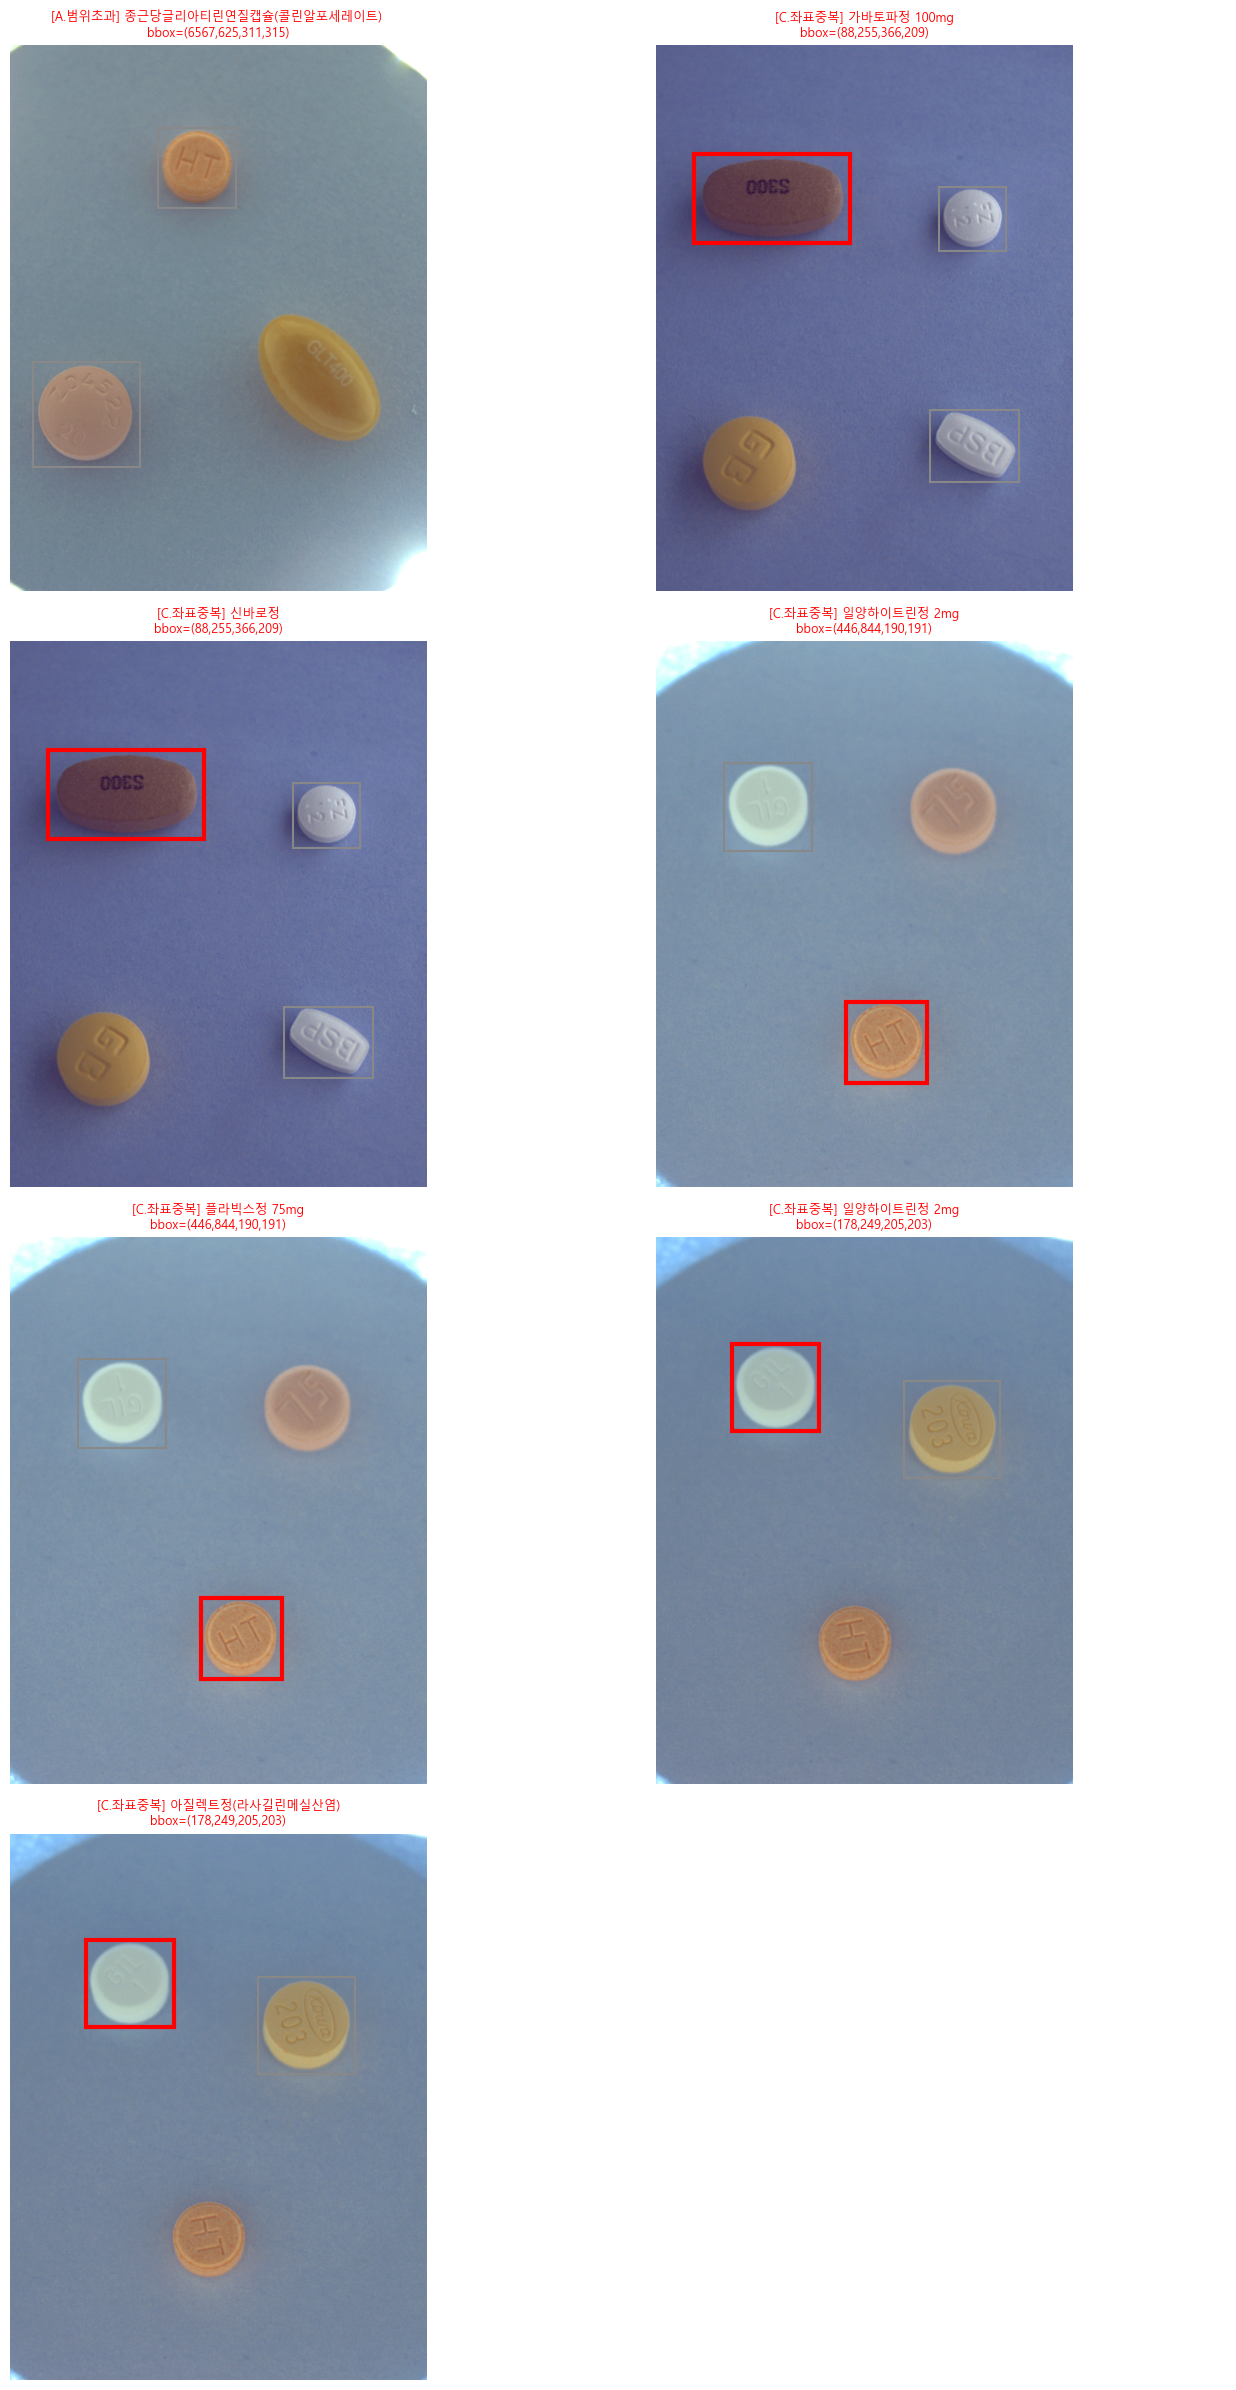

In [94]:
# ===== Cell 6-시각화: 이상 데이터 A/C 이미지 확인 =====
from PIL import Image
import matplotlib.patches as patches
import numpy as np
import os

# A: 범위 초과
A_vis = df[
    (df['bbox_x'] < 0) | (df['bbox_y'] < 0) |
    (df['bbox_x'] + df['bbox_w'] > df['img_w']) |
    (df['bbox_y'] + df['bbox_h'] > df['img_h'])
].copy()
A_vis['issue'] = 'A.범위초과'

# C: 좌표 중복
dup_mask = df.duplicated(subset=['file_name','bbox_x','bbox_y','bbox_w','bbox_h'], keep=False)
C_vis = df[dup_mask].sort_values(['file_name','bbox_x']).copy()
C_vis['issue'] = 'C.좌표중복'

vis = pd.concat([A_vis, C_vis], ignore_index=False)
print(f"시각화 대상: A {len(A_vis)}건 + C {len(C_vis)}건 = 총 {len(vis)}건")

n = len(vis)
cols = 2
rows = (n + cols - 1) // cols
fig, axes = plt.subplots(rows, cols, figsize=(14, 6*rows))
axes = np.atleast_1d(axes).flatten()

for i, (_, r) in enumerate(vis.iterrows()):
    ax = axes[i]
    img_path = os.path.join(IMG_DIR, r['file_name'])
    try:
        img = Image.open(img_path)
        ax.imshow(img)
        # 같은 이미지 내 다른 bbox는 회색으로 참고 표시
        same_img = df[df['file_name'] == r['file_name']]
        for _, s in same_img.iterrows():
            ax.add_patch(patches.Rectangle(
                (s['bbox_x'], s['bbox_y']), s['bbox_w'], s['bbox_h'],
                linewidth=1.5, edgecolor='#888', facecolor='none'))
        # 문제 bbox는 빨강 강조
        ax.add_patch(patches.Rectangle(
            (r['bbox_x'], r['bbox_y']), r['bbox_w'], r['bbox_h'],
            linewidth=3, edgecolor='red', facecolor='none'))
    except Exception as e:
        ax.text(0.5, 0.5, f'로드 실패\n{e}', ha='center', va='center')
    ax.set_title(f"[{r['issue']}] {r['category_name']}\n"
                 f"bbox=({r['bbox_x']},{r['bbox_y']},{r['bbox_w']},{r['bbox_h']})",
                 fontsize=9, color='red')
    ax.axis('off')

for j in range(n, len(axes)):
    axes[j].axis('off')

plt.tight_layout()
plt.show()

### 인사이트 (Cell 6)

**[A] 범위 초과 — 1건**
- `bbox_x=6567`, 이미지 너비(976)의 **약 6.7배** → 입력 오류 확정
- 빨간 박스가 첫 번째 이미지에서 **화면 밖**이라 보이지 않음 (시각적 증거)
- **학습 시 제외 또는 수정 필수**

**[B] area 불일치 — 6건**
- area_meta 와 w×h 차이 소수. 학습엔 bbox 좌표만 사용 → **무시 가능**

**[C] 좌표 중복 — 3쌍 (6건)**
동일 위치 bbox에 **서로 다른 클래스명 2개** 부여 → 하나의 알약을 두 이름으로 라벨링

| 쌍 | 알약 특징 | 라벨 1 | 라벨 2 |
|---|---|---|---|
| 1 | `S300` 각인 갈색 타원 | 가바토파정 100mg | 신바로정 |
| 2 | `HT` 각인 주황 원형 | 일양하이트린정 2mg | 플라빅스정 75mg |
| 3 | 흰색 원형 | 일양하이트린정 2mg | 아질렉트정(라사길린메실산염) |

- **라벨링 표준화 시급** → 동일 알약에 일관된 클래스 안 붙으면 분류 학습 성립 불가
- 원인 가능성: 촬영본 재사용 시 크로스 어노테이션, 또는 시각상 유사 알약 혼동

**우선 수정 순위**: **A (치명, 즉시 수정)** > **C (수작업 검수, 팀 합의 필요)** > B (무시)

# 📘 Cell 7 — 파일명 기대치 vs 실제 박스 수 (누락 탐지)

In [95]:
# 파일명에서 기대되는 category_id 집합 추출
def expected_cats_from_filename(fn):
    prefix = fn.split('_')[0]  # 예: "K-003351-013900-021325"
    segs = prefix.split('-')[1:]  # ['003351','013900','021325']
    return set(int(s) for s in segs)

# 이미지별 실제 박스의 category_id 집합
actual_cats = df.groupby('file_name')['category_id'].apply(set).to_dict()

missing_rows = []
for fn, act in actual_cats.items():
    exp = expected_cats_from_filename(fn)
    miss = exp - act
    extra = act - exp
    if miss or extra:
        missing_rows.append({
            'file_name': fn,
            'expected_n': len(exp),
            'actual_n': len(act),
            'missing_cats': sorted(miss),
            'extra_cats': sorted(extra),
        })

miss_df = pd.DataFrame(missing_rows)
print(f'누락/추가 이상 이미지: {len(miss_df)}건')
print()
if len(miss_df) > 0:
    # 누락된 알약 이름까지 표시
    for _, row in miss_df.iterrows():
        miss_names = [class_name_map.get(c, f'id={c}') for c in row['missing_cats']]
        extra_names = [class_name_map.get(c, f'id={c}') for c in row['extra_cats']]
        print(f"▸ {row['file_name']}")
        print(f"   기대 {row['expected_n']}개 / 실제 {row['actual_n']}개")
        if row['missing_cats']:
            print(f"   ❌ 누락: {row['missing_cats']} → {miss_names}")
        if row['extra_cats']:
            print(f"   ⚠️ 추가: {row['extra_cats']} → {extra_names}")
        print()

# 누락 클래스별 빈도 집계
from collections import Counter
miss_counter = Counter()
for r in missing_rows:
    for c in r['missing_cats']:
        miss_counter[c] += 1
print('=== 어떤 클래스가 자주 누락되는가? ===')
for cid, cnt in miss_counter.most_common():
    print(f'  id={cid}  누락 {cnt}회  ({class_name_map.get(cid, "?")})')

누락/추가 이상 이미지: 8건

▸ K-003351-013900-021325_0_2_0_2_70_000_200.png
   기대 3개 / 실제 2개
   ❌ 누락: [3351] → ['일양하이트린정 2mg']

▸ K-003351-013900-036637_0_2_0_2_70_000_200.png
   기대 3개 / 실제 2개
   ❌ 누락: [3351] → ['일양하이트린정 2mg']

▸ K-003351-020014-022074_0_2_0_2_90_000_200.png
   기대 3개 / 실제 2개
   ❌ 누락: [20014] → ['마도파정']

▸ K-003351-021325-032310_0_2_0_2_90_000_200.png
   기대 3개 / 실제 2개
   ❌ 누락: [32310] → ['글리아타민연질캡슐']

▸ K-003351-032310-038162_0_2_0_2_70_000_200.png
   기대 3개 / 실제 2개
   ❌ 누락: [3351] → ['일양하이트린정 2mg']

▸ K-003351-033880-038162_0_2_0_2_75_000_200.png
   기대 3개 / 실제 2개
   ❌ 누락: [33880] → ['글리틴정(콜린알포세레이트)']

▸ K-003351-035206-041768_0_2_0_2_70_000_200.png
   기대 3개 / 실제 2개
   ❌ 누락: [3351] → ['일양하이트린정 2mg']

▸ K-003544-004543-012247-016548_0_2_0_2_90_000_200.png
   기대 4개 / 실제 3개
   ❌ 누락: [4543] → ['에어탈정(아세클로페낙)']

=== 어떤 클래스가 자주 누락되는가? ===
  id=3351  누락 4회  (일양하이트린정 2mg)
  id=20014  누락 1회  (마도파정)
  id=32310  누락 1회  (글리아타민연질캡슐)
  id=33880  누락 1회  (글리틴정(콜린알포세레이트))
  id=4543  누락 1회  (에어탈정(아세

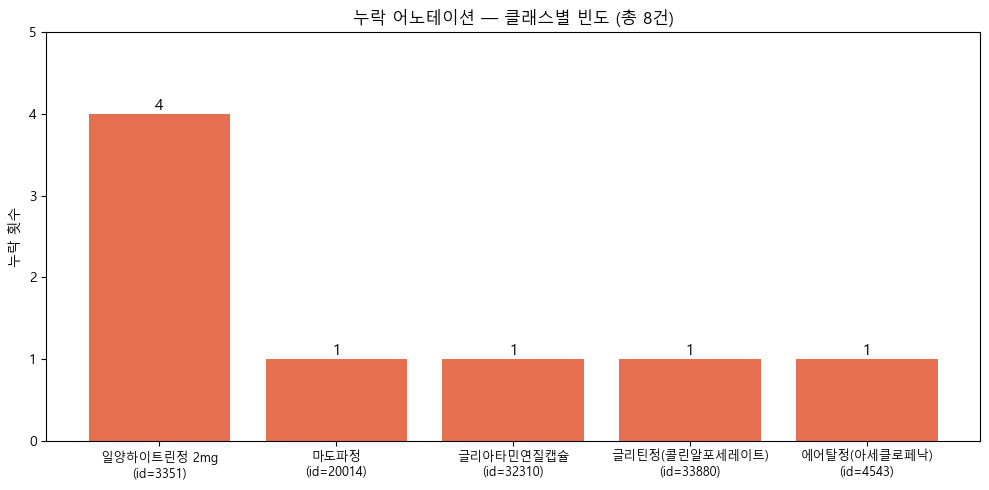

In [96]:
# ===== Cell 7-시각화: 누락 클래스 빈도 =====
if miss_counter:
    cids = [c for c, _ in miss_counter.most_common()]
    cnts = [n for _, n in miss_counter.most_common()]
    names = [f"{class_name_map.get(c, '?')}\n(id={c})" for c in cids]

    fig, ax = plt.subplots(figsize=(10, 5))
    bars = ax.bar(range(len(cids)), cnts, color='#e76f51')
    for b, v in zip(bars, cnts):
        ax.text(b.get_x() + b.get_width()/2, v + 0.05, str(v),
                ha='center', fontsize=11)
    ax.set_xticks(range(len(cids)))
    ax.set_xticklabels(names, rotation=0, fontsize=9)
    ax.set_ylabel('누락 횟수')
    ax.set_title(f'누락 어노테이션 — 클래스별 빈도 (총 {sum(cnts)}건)')
    ax.set_ylim(0, max(cnts) + 1)
    plt.tight_layout()
    plt.show()
else:
    print("누락 없음")

### 인사이트 (Cell 7)

- **총 8건의 누락 어노테이션** — 파일명에서 기대되는 category_id가 실제 bbox에 없음
- **id=3351 (일양하이트린정 2mg)이 4회로 압도적 1위** — 전체 누락의 절반
- 나머지 4개 클래스 (20014 / 32310 / 33880 / 4543)는 각 1회씩
- **Cell 6의 C쌍 2·3과 동일 알약** → `HT` 각인 일양하이트린정이 **라벨 혼동 + 누락** 양쪽에서 문제 반복 확인
- **팀미팅 핵심**: 일양하이트린정 관련 어노테이션 전수 재검토 필요
- Cell 8에서 **누락 8장 실제 이미지 위에 위치 시각화** → 박스 없는 알약이 실제 보이는지 눈으로 확인

# 📘 Cell 8 — 누락 이미지 시각화 (눈으로 확인)

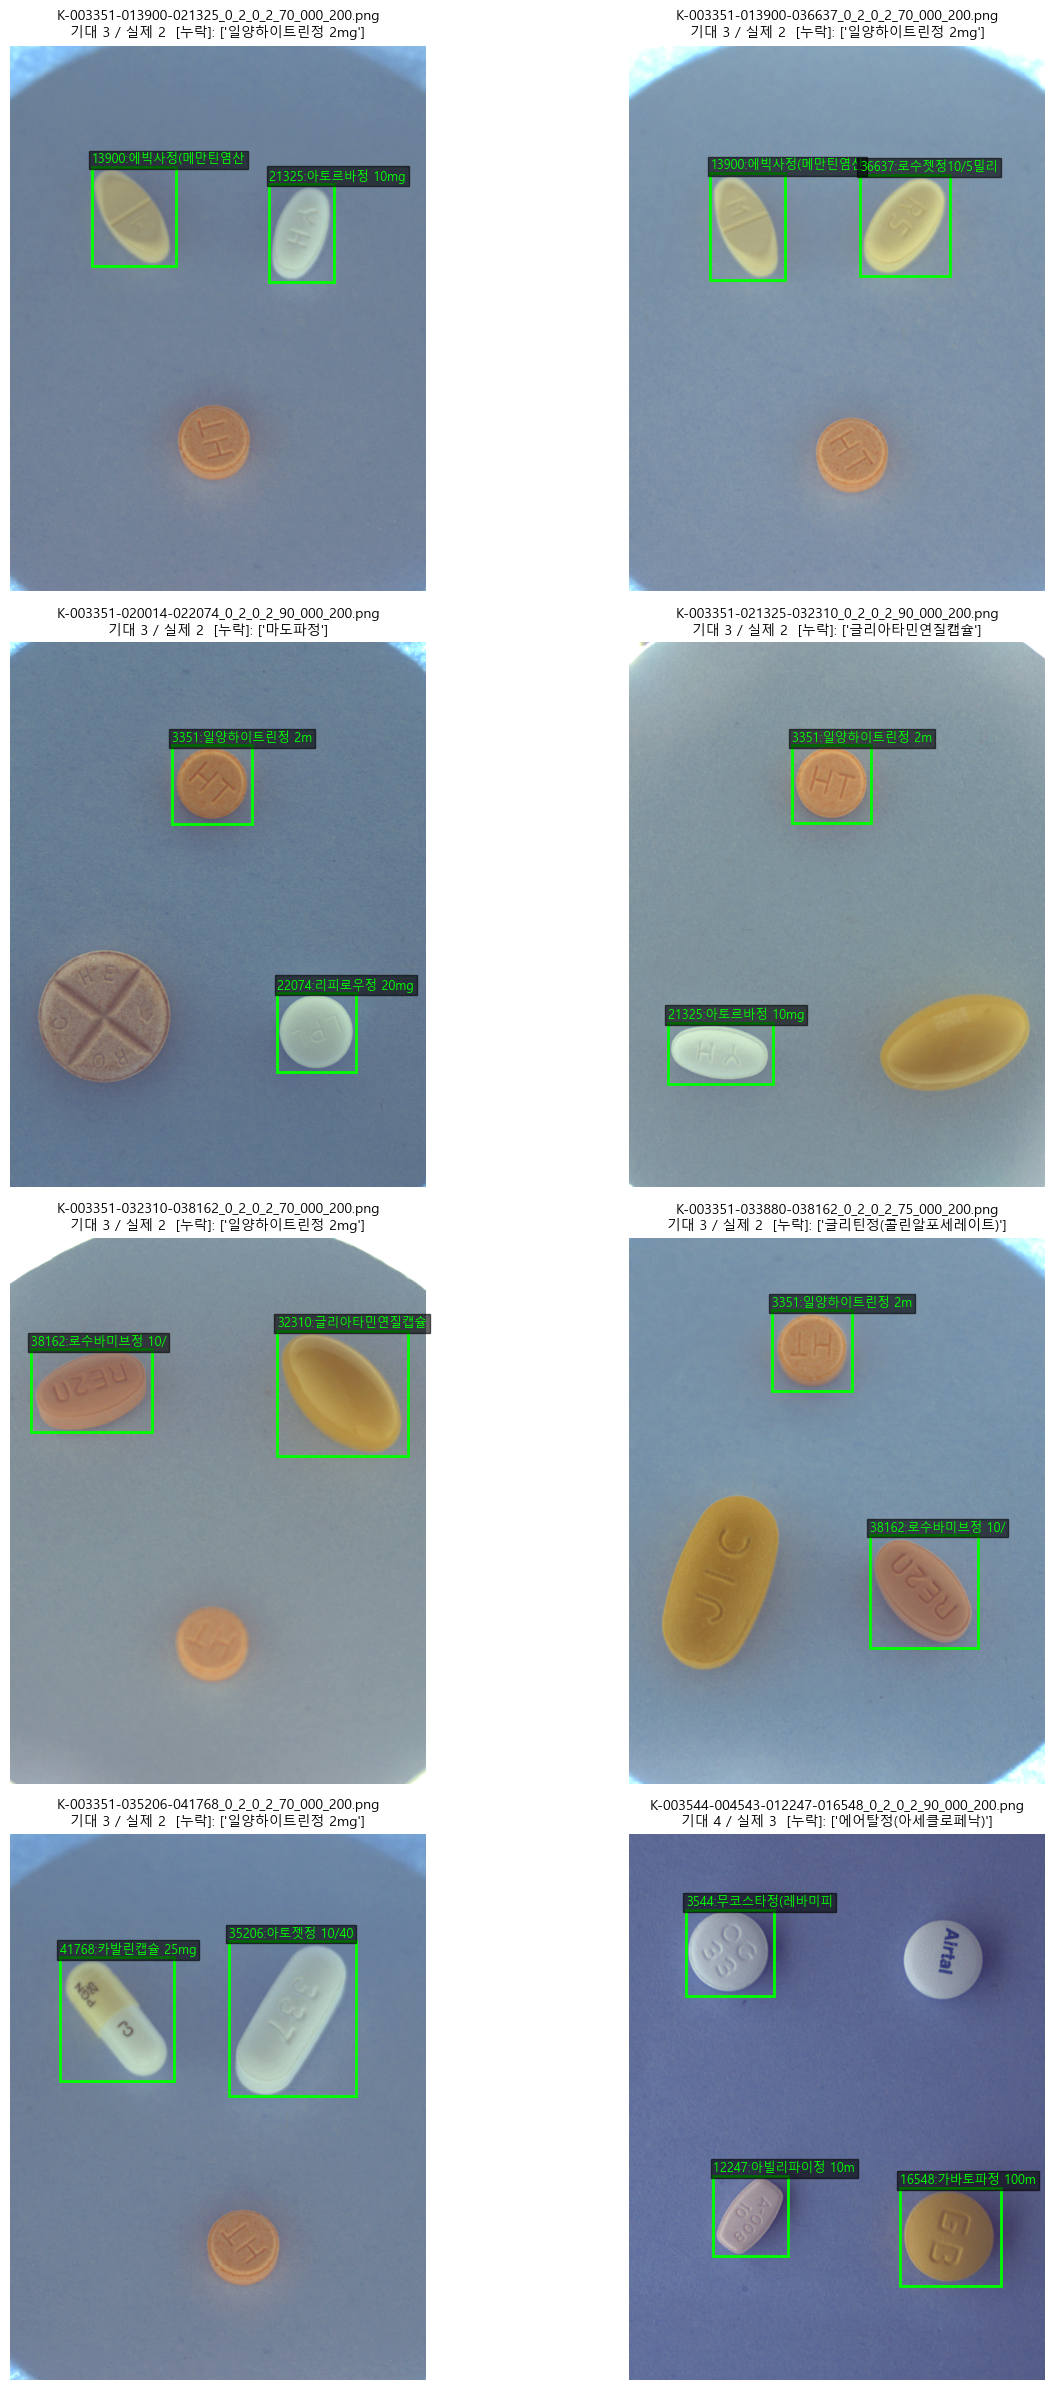

In [97]:
import matplotlib.patches as patches

def draw_boxes(ax, img, rows, color_palette=None):
    ax.imshow(img)
    for _, r in rows.iterrows():
        rect = patches.Rectangle(
            (r['bbox_x'], r['bbox_y']), r['bbox_w'], r['bbox_h'],
            linewidth=2, edgecolor='lime', facecolor='none'
        )
        ax.add_patch(rect)
        ax.text(r['bbox_x'], r['bbox_y'] - 8,
                f"{r['category_id']}:{r['category_name'][:10]}",
                color='lime', fontsize=9,
                bbox=dict(facecolor='black', alpha=0.6, pad=2))
    ax.axis('off')

# 누락된 8장 모두 시각화
n = len(miss_df)
cols = 2
rows_n = (n + cols - 1) // cols
fig, axes = plt.subplots(rows_n, cols, figsize=(14, 6 * rows_n))
axes = axes.flatten() if n > 1 else [axes]

for i, (_, row) in enumerate(miss_df.iterrows()):
    fn = row['file_name']
    img_path = IMG_DIR / fn
    img = Image.open(img_path)
    anns = df[df['file_name'] == fn]
    draw_boxes(axes[i], img, anns)
    miss_names = [class_name_map.get(c, f'id={c}') for c in row['missing_cats']]
    axes[i].set_title(
        f"{fn}\n기대 {row['expected_n']} / 실제 {row['actual_n']}  [누락]: {miss_names}",
        fontsize=10
    )
    

for j in range(i + 1, len(axes)):
    axes[j].axis('off')

plt.tight_layout()
plt.show()

### 인사이트 (Cell 8)

- **누락 8장 모두 알약이 실제로 보임** → 어노테이션 실수 확정 (학습 시 false negative 유발)
- **파일명 prefix = 기대 클래스**인데 그중 하나가 박스 없이 누락된 패턴 (예: `K-003351-*` → id 3351 기대 → 누락)
- **id=3351 일양하이트린정 2mg 4건**: 8건 중 절반. Cell 6 C쌍(2·3)과 겹치는 동일 클래스 → **어노테이션 전수 재검토 필요**
- 나머지 4건은 각 1회씩 (마도파정 · 글리아타민연질캡슐 · 글리틴정 · 에어탈정)

# 📘 Cell 9 — 이미지 파일 무결성 체크 (깨진 파일 / 메타-실제 불일치)

In [98]:
from PIL import Image, UnidentifiedImageError

def check_images(folder, label):
    files = sorted(os.listdir(folder))
    broken = []
    size_mismatch = []
    actual_sizes = Counter()
    for fn in files:
        p = folder / fn
        try:
            with Image.open(p) as im:
                im.verify()  # 파일 구조 검증
            with Image.open(p) as im:
                w, h = im.size
                actual_sizes[(w, h)] += 1
        except (UnidentifiedImageError, OSError, Exception) as e:
            broken.append((fn, str(e)))
            continue
        # train의 경우 메타와 실제 해상도 비교
        if label == 'train':
            meta_rows = df[df['file_name'] == fn]
            if len(meta_rows) > 0:
                meta_w = meta_rows.iloc[0]['img_w']
                meta_h = meta_rows.iloc[0]['img_h']
                if (w, h) != (meta_w, meta_h):
                    size_mismatch.append((fn, (w, h), (meta_w, meta_h)))
    return broken, size_mismatch, actual_sizes

print('=== TRAIN IMAGES ===')
tr_broken, tr_mismatch, tr_sizes = check_images(IMG_DIR, 'train')
print(f'깨진 파일: {len(tr_broken)}')
for b in tr_broken[:5]: print(' ', b)
print(f'메타↔실제 해상도 불일치: {len(tr_mismatch)}')
for m in tr_mismatch[:5]: print(' ', m)
print(f'실제 해상도 분포: {dict(tr_sizes)}')

print('\n=== TEST IMAGES ===')
te_broken, _, te_sizes = check_images(TEST_DIR, 'test')
print(f'깨진 파일: {len(te_broken)}')
for b in te_broken[:5]: print(' ', b)
print(f'실제 해상도 분포 (상위 5): {dict(te_sizes.most_common(5))}')
print(f'해상도 종류 수: {len(te_sizes)}')

=== TRAIN IMAGES ===
깨진 파일: 0
메타↔실제 해상도 불일치: 0
실제 해상도 분포: {(976, 1280): 232}

=== TEST IMAGES ===
깨진 파일: 0
실제 해상도 분포 (상위 5): {(976, 1280): 842}
해상도 종류 수: 1


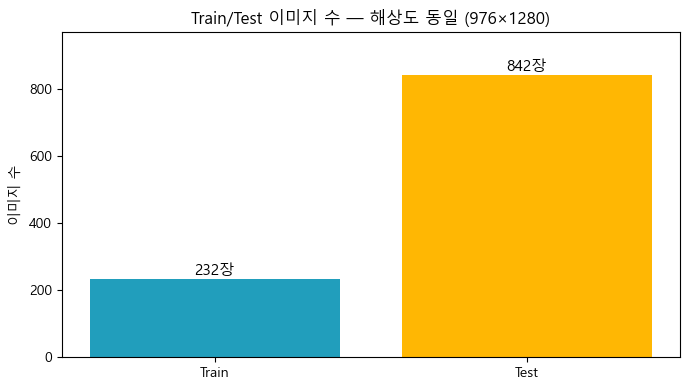

In [99]:
fig, ax = plt.subplots(figsize=(7, 4))
labels = ['Train', 'Test']
counts = [sum(tr_sizes.values()), sum(te_sizes.values())]
bars = ax.bar(labels, counts, color=['#219ebc', '#ffb703'])
for b, c in zip(bars, counts):
    ax.text(b.get_x() + b.get_width()/2, c, f'{c}장', ha='center', va='bottom', fontsize=11)
ax.set_ylabel('이미지 수')
ax.set_title('Train/Test 이미지 수 — 해상도 동일 (976×1280)', fontsize=12)
ax.set_ylim(0, max(counts) * 1.15)
plt.tight_layout(); plt.show()

### 인사이트 (Cell 9)

- 깨진 파일 **0건** / 메타↔실제 해상도 불일치 **0건** (train 232, test 842 전수 검증)
- Train/Test **동일 단일 해상도 976×1280** → resize 전처리 불필요, 모델 input size 고정 가능
- Train 232 : Test 842 = **1 : 3.6** → Test 추론량 많지만 **학습 데이터가 병목**
- 232장 / 763 어노테이션 → 소량 데이터셋 → 과적합 리스크 → 증강 필수

# 📘 Cell 10 — JSON image_id 필드 일관성 체크

In [100]:
# 각 JSON에서 image_id와 file_name을 뽑아서, 같은 file_name인데 image_id가 다른 케이스 찾기
from collections import defaultdict

file_to_ids = defaultdict(set)         # file_name -> set of image_id (images[0].id)
file_to_ann_img_ids = defaultdict(set) # file_name -> set of annotation.image_id

for jf in json_files:
    with open(jf, 'r', encoding='utf-8') as f:
        d = json.load(f)
    fn = d['images'][0]['file_name']
    img_id = d['images'][0]['id']
    file_to_ids[fn].add(img_id)
    for ann in d['annotations']:
        file_to_ann_img_ids[fn].add(ann['image_id'])

# 같은 이미지인데 image_id가 여러 개인 경우
img_id_conflict = {fn: ids for fn, ids in file_to_ids.items() if len(ids) > 1}
# image_id 참조가 images[0].id와 다른 경우
mismatch = []
for fn in file_to_ids:
    if file_to_ids[fn] != file_to_ann_img_ids[fn]:
        mismatch.append((fn, file_to_ids[fn], file_to_ann_img_ids[fn]))

# 서로 다른 파일인데 같은 image_id 쓰는 경우 (COCO 통합 시 충돌)
id_to_files = defaultdict(set)
for fn, ids in file_to_ids.items():
    for i in ids:
        id_to_files[i].add(fn)
id_collision = {i: fns for i, fns in id_to_files.items() if len(fns) > 1}

print(f'[A] 같은 file_name인데 image_id가 여러 개인 경우: {len(img_id_conflict)}건')
for fn, ids in list(img_id_conflict.items())[:5]:
    print(f'   {fn}  -> ids={ids}')

print(f'\n[B] images[0].id ≠ annotations[].image_id 인 경우: {len(mismatch)}건')
for m in mismatch[:5]: print(f'   {m}')

print(f'\n[C] 서로 다른 이미지가 같은 image_id 공유: {len(id_collision)}건')
for i, fns in list(id_collision.items())[:5]:
    print(f'   id={i}  files={list(fns)[:3]}{"..." if len(fns)>3 else ""}')

[A] 같은 file_name인데 image_id가 여러 개인 경우: 0건

[B] images[0].id ≠ annotations[].image_id 인 경우: 0건

[C] 서로 다른 이미지가 같은 image_id 공유: 0건


### 인사이트 (Cell 10)

- [A] 같은 파일 내 image_id 복수: **0건**
- [B] `images[0].id ≠ annotations[].image_id`: **0건**
- [C] 다른 파일이 같은 image_id 공유: **0건**
- JSON 구조 무결성 완전 clean → 232개 JSON을 **단일 COCO로 안전 병합 가능**

# 📘 Cell 11 — 파일명 variation 코드 분포

In [101]:
# 파일명 형식: K-xxxxxx-xxxxxx-..._A_B_C_D_E_F_G.png
# 접두 K-...- 조합 / 뒤 언더스코어 분리된 코드들 분석

variation_tokens = []
for fn in df['file_name'].unique():
    stem = fn.rsplit('.', 1)[0]  # .png 제거
    parts = stem.split('_')
    combo = parts[0]                  # K-xxxx-xxxx-...
    tokens = parts[1:]                # ['0','2','0','2','70','000','200']
    variation_tokens.append(tokens)

# 토큰 개수 일관성
token_lens = Counter(len(t) for t in variation_tokens)
print(f'파일당 variation 토큰 개수 분포: {dict(token_lens)}')

# 각 위치별 값 분포 (토큰 7개로 가정)
n_positions = max(token_lens.keys())
print(f'\n위치별 고유 값 분포:')
for i in range(n_positions):
    vals = Counter(t[i] if i < len(t) else None for t in variation_tokens)
    print(f'  pos {i}: {len(vals)}종  {dict(vals.most_common())}')

# 어떤 조합(K-...)이 몇 가지 variation을 가지는지
from collections import defaultdict
combo_to_files = defaultdict(list)
for fn in df['file_name'].unique():
    combo = fn.split('_')[0]
    combo_to_files[combo].append(fn)

vari_counts = Counter(len(v) for v in combo_to_files.values())
print(f'\n조합별 variation 이미지 수 분포: {dict(vari_counts)}')
print(f'고유 조합 수: {len(combo_to_files)}')

파일당 variation 토큰 개수 분포: {7: 232}

위치별 고유 값 분포:
  pos 0: 1종  {'0': 232}
  pos 1: 1종  {'2': 232}
  pos 2: 2종  {'0': 228, '1': 4}
  pos 3: 1종  {'2': 232}
  pos 4: 3종  {'90': 85, '75': 75, '70': 72}
  pos 5: 1종  {'000': 232}
  pos 6: 1종  {'200': 232}

조합별 variation 이미지 수 분포: {3: 40, 2: 38, 1: 36}
고유 조합 수: 114


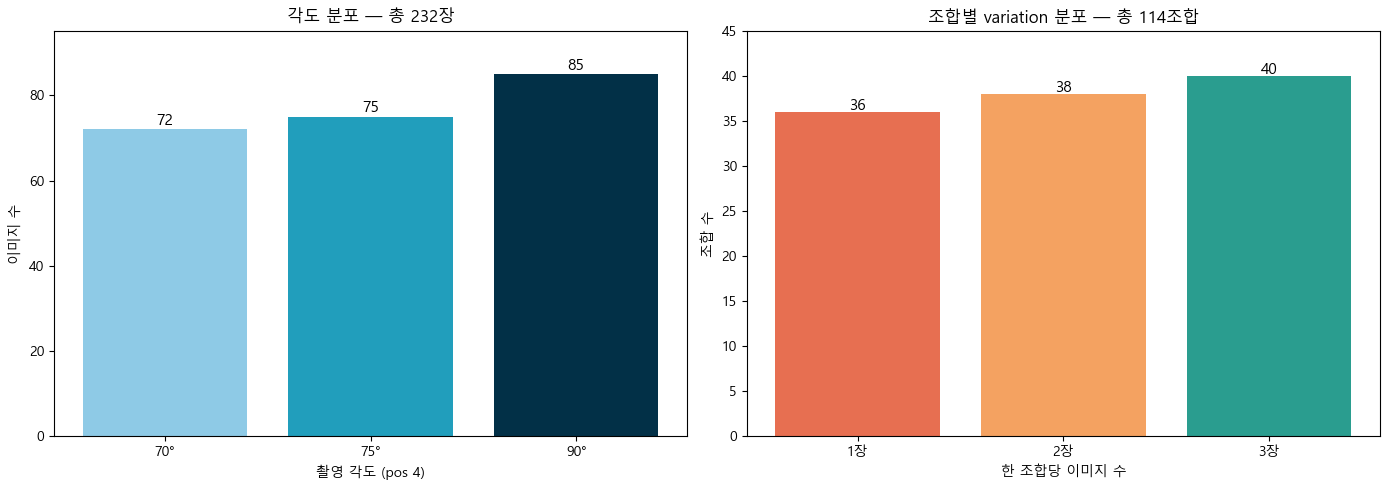

In [102]:
# ===== Cell 11-시각화: 각도 분포 + 조합별 variation =====
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 좌: 각도 분포 (pos 4)
angle_dist = Counter(t[4] for t in variation_tokens)
angles_sorted = sorted(angle_dist.items(), key=lambda x: int(x[0]))
labels = [f'{a}°' for a, _ in angles_sorted]
counts = [c for _, c in angles_sorted]
bars = axes[0].bar(labels, counts, color=['#8ecae6', '#219ebc', '#023047'])
for b, v in zip(bars, counts):
    axes[0].text(b.get_x() + b.get_width()/2, v + 1, str(v),
                 ha='center', fontsize=11)
axes[0].set_xlabel('촬영 각도 (pos 4)')
axes[0].set_ylabel('이미지 수')
axes[0].set_title(f'각도 분포 — 총 {sum(counts)}장')
axes[0].set_ylim(0, max(counts) + 10)

# 우: 조합별 variation 이미지 수
vari_sorted = sorted(vari_counts.items())
labels_v = [f'{k}장' for k, _ in vari_sorted]
counts_v = [v for _, v in vari_sorted]
bars = axes[1].bar(labels_v, counts_v, color=['#e76f51', '#f4a261', '#2a9d8f'])
for b, v in zip(bars, counts_v):
    axes[1].text(b.get_x() + b.get_width()/2, v + 0.3, str(v),
                 ha='center', fontsize=11)
axes[1].set_xlabel('한 조합당 이미지 수')
axes[1].set_ylabel('조합 수')
axes[1].set_title(f'조합별 variation 분포 — 총 {sum(counts_v)}조합')
axes[1].set_ylim(0, max(counts_v) + 5)

plt.tight_layout()
plt.show()

### 인사이트 (Cell 11)

- 파일당 토큰 **7개 고정** → 파일명 포맷 완전 일관 (232장 전수)
- pos 0, 1, 3, 5, 6 = **단일값 상수** → 학습 데이터셋 내 variation 없음
- **pos 2**: '0' 228장 / **'1' 4장** → 의미 불명 이상 4건 (이슈 F, Cell 12에서 추적)
- **pos 4 = 촬영 각도 (70°/75°/90°)** → 72 / 75 / 85장으로 **3종 고르게 분포**
- 고유 조합 **114개**, 이미지 수 분포 **{3장: 40, 2장: 38, 1장: 36}** → **35%만 각도 풀커버**, 65%는 일부 각도 누락 (이슈 G)

# 📘 Cell 12-1 — 이슈 F, G 상세 파악

In [103]:
# 이슈 F: pos 2='1'인 4건 조사
pos2_one = [fn for fn in df['file_name'].unique() if fn.split('_')[3] == '1']
print(f'[이슈 F] pos 2 == "1" 인 파일 {len(pos2_one)}건:')
for fn in pos2_one:
    print(f'  {fn}')

# 이슈 G: 조합별로 어떤 각도가 누락됐는지
print(f'\n[이슈 G] 조합별 각도 variation 상세:')
combo_angles = defaultdict(set)
for fn in df['file_name'].unique():
    parts = fn.rsplit('.', 1)[0].split('_')
    combo = parts[0]
    angle = parts[5]  # pos 4 (0-index), but in split it's index 5 because combo is parts[0]
    combo_angles[combo].add(angle)

# 각 조합에 어떤 각도가 있는지 통계
angle_set_counter = Counter()
for combo, angles in combo_angles.items():
    angle_set_counter[tuple(sorted(angles))] += 1

print('  (가진 각도 조합) -> 조합 수')
for angles, cnt in sorted(angle_set_counter.items(), key=lambda x: -x[1]):
    print(f'  {angles}  -> {cnt}개 조합')

# 1장만 있는 조합 36개 목록
only_one = [(c, sorted(a)) for c, a in combo_angles.items() if len(a) == 1]
print(f'\n  ▸ 1장만 있는 조합 {len(only_one)}개 (각도 2개 누락):')
for c, a in only_one[:10]:
    print(f'    {c}  only {a}')
if len(only_one) > 10:
    print(f'    ... 외 {len(only_one)-10}개')

[이슈 F] pos 2 == "1" 인 파일 4건:
  K-003351-019232-029667_0_2_1_2_70_000_200.png
  K-003351-019232-029667_0_2_1_2_90_000_200.png
  K-003351-020014-036637_0_2_1_2_75_000_200.png
  K-003351-020014-036637_0_2_1_2_90_000_200.png

[이슈 G] 조합별 각도 variation 상세:
  (가진 각도 조합) -> 조합 수
  ('70', '75', '90')  -> 40개 조합
  ('90',)  -> 16개 조합
  ('70', '90')  -> 15개 조합
  ('75', '90')  -> 14개 조합
  ('75',)  -> 12개 조합
  ('70', '75')  -> 9개 조합
  ('70',)  -> 8개 조합

  ▸ 1장만 있는 조합 36개 (각도 2개 누락):
    K-003351-003832-016688  only ['70']
    K-003351-003832-020238  only ['90']
    K-003351-003832-029667  only ['75']
    K-003351-003832-036637  only ['90']
    K-003351-013900-020238  only ['90']
    K-003351-013900-035206  only ['70']
    K-003351-016232-018357  only ['75']
    K-003351-016232-031863  only ['90']
    K-003351-016232-032310  only ['90']
    K-003351-016232-033880  only ['75']
    ... 외 26개


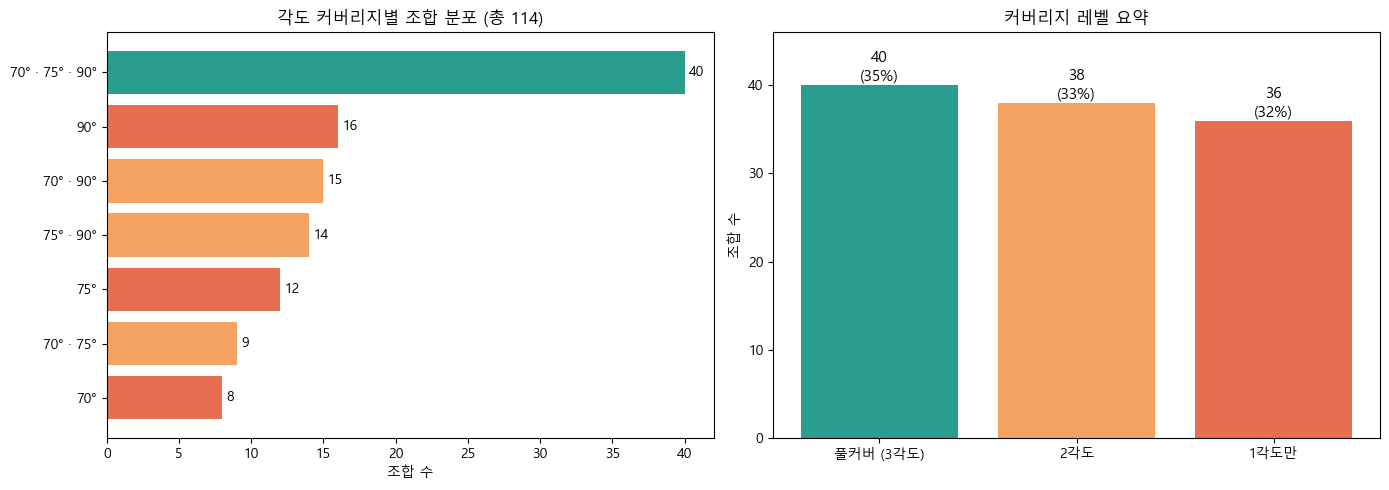

In [104]:
# ===== Cell 12-1 시각화: 각도 커버리지 =====
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 좌: 각도 조합 7종 분포 (수평바, 커버리지별 색상)
angle_set_sorted = sorted(angle_set_counter.items(), key=lambda x: -x[1])
labels = [' · '.join(f'{a}°' for a in angles) for angles, _ in angle_set_sorted]
counts = [c for _, c in angle_set_sorted]
colors = ['#2a9d8f' if len(a)==3 else '#f4a261' if len(a)==2 else '#e76f51'
          for a, _ in angle_set_sorted]
bars = axes[0].barh(range(len(labels)), counts, color=colors)
for i, v in enumerate(counts):
    axes[0].text(v + 0.3, i, str(v), va='center', fontsize=10)
axes[0].set_yticks(range(len(labels)))
axes[0].set_yticklabels(labels, fontsize=10)
axes[0].invert_yaxis()
axes[0].set_xlabel('조합 수')
axes[0].set_title('각도 커버리지별 조합 분포 (총 114)')

# 우: 커버리지 레벨 요약
level_counts = {'풀커버 (3각도)': 0, '2각도': 0, '1각도만': 0}
for angles, c in angle_set_counter.items():
    key = '풀커버 (3각도)' if len(angles)==3 else '2각도' if len(angles)==2 else '1각도만'
    level_counts[key] += c

level_labels = list(level_counts.keys())
level_vals = list(level_counts.values())
bars = axes[1].bar(level_labels, level_vals, color=['#2a9d8f', '#f4a261', '#e76f51'])
for b, v in zip(bars, level_vals):
    pct = v / sum(level_vals) * 100
    axes[1].text(b.get_x() + b.get_width()/2, v + 0.5,
                 f'{v}\n({pct:.0f}%)', ha='center', fontsize=11)
axes[1].set_ylabel('조합 수')
axes[1].set_title('커버리지 레벨 요약')
axes[1].set_ylim(0, max(level_vals) + 6)

plt.tight_layout()
plt.show()

### 인사이트 (Cell 12-1)

- **이슈 F — pos 2 = '1' 4건**: 전부 `K-003351` 조합 소속, **id 19232 / 20014** 관련 파일에 집중 → 특정 촬영 세션 한정 변이로 추정
- **이슈 G — 각도 커버리지**: 114조합 중 풀커버(70·75·90°) **40조합 (35%)** / 2개 각도 38조합 (33%) / **1개 각도만 36조합 (32%)**
- **1장만 있는 36조합** → 해당 알약 세트가 **특정 각도 1개에서만 학습됨** → 다른 각도에서 예측 시 **일반화 리스크**
- 누락된 각도가 많은 조합일수록 test 시 미학습 각도 맞닥뜨릴 확률 증가 → **angle augmentation 필수**

# 📘 Cell 12-2 — 조합 폴더 내부 알약별 이미지 set 일치 여부

In [105]:
# 조합 폴더 구조: train_annotations/<combo>_json/<K-pill>/*.json
# 같은 조합 안에서 알약 A, B, C, D가 동일한 이미지 파일 set을 커버하는지 확인

ann_structure = defaultdict(lambda: defaultdict(set))
# ann_structure[combo][pill] = {image_file_name, ...}

for jf in json_files:
    parts = jf.replace(os.sep, '/').split('/')
    combo_folder = parts[-3]  # K-..._json
    pill_folder = parts[-2]   # K-xxxxxx
    with open(jf, 'r', encoding='utf-8') as f:
        d = json.load(f)
    fn = d['images'][0]['file_name']
    ann_structure[combo_folder][pill_folder].add(fn)

# 각 조합 안에서 알약별 이미지 set이 서로 일치하는지
mismatches = []
for combo, pills in ann_structure.items():
    pill_names = list(pills.keys())
    all_images = set().union(*pills.values())
    # 각 알약이 커버 못 하는 이미지 찾기
    for pill in pill_names:
        missing = all_images - pills[pill]
        if missing:
            mismatches.append({
                'combo': combo,
                'pill_missing_for': pill,
                'n_missing': len(missing),
                'missing_images': sorted(missing),
            })

print(f'조합 내부 알약별 이미지 set 불일치: {len(mismatches)}건')
for m in mismatches:
    print(f'\n▸ {m["combo"]}')
    print(f'  알약 {m["pill_missing_for"]} 박스가 빠진 이미지 {m["n_missing"]}장:')
    for img in m['missing_images']:
        print(f'    {img}')

조합 내부 알약별 이미지 set 불일치: 8건

▸ K-003351-013900-021325_json
  알약 K-003351 박스가 빠진 이미지 1장:
    K-003351-013900-021325_0_2_0_2_70_000_200.png

▸ K-003351-013900-036637_json
  알약 K-003351 박스가 빠진 이미지 1장:
    K-003351-013900-036637_0_2_0_2_70_000_200.png

▸ K-003351-020014-022074_json
  알약 K-020014 박스가 빠진 이미지 1장:
    K-003351-020014-022074_0_2_0_2_90_000_200.png

▸ K-003351-021325-032310_json
  알약 K-032310 박스가 빠진 이미지 1장:
    K-003351-021325-032310_0_2_0_2_90_000_200.png

▸ K-003351-032310-038162_json
  알약 K-003351 박스가 빠진 이미지 1장:
    K-003351-032310-038162_0_2_0_2_70_000_200.png

▸ K-003351-033880-038162_json
  알약 K-033880 박스가 빠진 이미지 1장:
    K-003351-033880-038162_0_2_0_2_75_000_200.png

▸ K-003351-035206-041768_json
  알약 K-003351 박스가 빠진 이미지 1장:
    K-003351-035206-041768_0_2_0_2_70_000_200.png

▸ K-003544-004543-012247-016548_json
  알약 K-004543 박스가 빠진 이미지 1장:
    K-003544-004543-012247-016548_0_2_0_2_90_000_200.png


### 인사이트 (Cell 12-2)

- 조합 내부 알약별 이미지 set 불일치 **8건** → Cell 7/8의 누락 8건과 **완전 동일** (같은 현상, 다른 검증 경로)
- 8건 중 **7건이 K-003351 조합** (일양하이트린정 2mg 관련 집중) / 1건은 K-003544 (에어탈정)
- 파일명 기준(Cell 7) / 시각 검증(Cell 8) / 조합 폴더 기준(Cell 12-2) **3가지 경로 모두 동일 8장 지적** → 누락 100% 확정
- 수정/제외 의사결정만 남음

# 📘 Cell 13 — extra_cats (파일명 기대 밖 박스)

In [106]:
# ===== Cell 13: extra_cats (파일명 기대 밖 박스) =====
extra_only = miss_df[miss_df['extra_cats'].apply(len) > 0].copy()
print(f'extra_cats 존재 건수: {len(extra_only)} / 전체 miss_df {len(miss_df)}건')

if len(extra_only) > 0:
    extra_counter = Counter()
    for r in extra_only.itertuples():
        for c in r.extra_cats:
            extra_counter[c] += 1

    print('\n[extra 클래스 빈도]')
    for cid, cnt in extra_counter.most_common():
        print(f'  id={cid:<5} ({class_name_map.get(cid, "?"):<30}) : {cnt}건')

    print('\n[파일별 상세]')
    for _, row in extra_only.iterrows():
        extra_names = [class_name_map.get(c, f'id={c}') for c in row['extra_cats']]
        miss_names = [class_name_map.get(c, f'id={c}') for c in row['missing_cats']]
        print(f"  {row['file_name']}")
        print(f"    기대 {row['expected_n']} / 실제 {row['actual_n']}")
        print(f"    누락: {miss_names if row['missing_cats'] else '없음'}")
        print(f"    추가: {extra_names}")
else:
    print('\n→ extra_cats 이상 없음 (모든 박스가 파일명 기대 범위 안)')

extra_cats 존재 건수: 0 / 전체 miss_df 8건

→ extra_cats 이상 없음 (모든 박스가 파일명 기대 범위 안)


### 인사이트 (Cell 13)

- **extra_cats 0건** — 파일명 기대 밖에 찍힌 박스 **없음**
- miss_df 8건은 전부 `missing_cats`만 있고 `extra_cats`는 비어있음 → Cell 7에서 본 누락 8건은 순수 "기대한 박스가 없는 케이스"이고, **엉뚱한 클래스로 오탐된 라벨은 없음**
- **결론**: 라벨러가 파일명 기대 범위를 벗어난 박스를 추가 생성하지 않았음 → 라벨링 규율은 지켜졌고, Cell 7의 누락 8건만 해결하면 됨
- **시각화 생략 사유**: extra_cats 0건 (시각화할 대상 없음)

# 📘 Cell 14 — category_id ↔ category_name 일관성

In [107]:
# ===== Cell 14: category_id ↔ category_name 일관성 =====
from collections import defaultdict

id_to_names = defaultdict(set)
name_to_ids = defaultdict(set)

for jp in json_files:
    with open(jp, encoding='utf-8') as f:
        data = json.load(f)
    for cat in data.get('categories', []):
        cid = cat.get('id')
        cname = cat.get('name')
        if cid is not None and cname is not None:
            id_to_names[cid].add(cname)
            name_to_ids[cname].add(cid)

print(f'고유 category_id: {len(id_to_names)}개')
print(f'고유 category_name: {len(name_to_ids)}개')

id_conflicts = {cid: names for cid, names in id_to_names.items() if len(names) > 1}
name_conflicts = {cname: ids for cname, ids in name_to_ids.items() if len(ids) > 1}

print(f'\n[id 1개 → name 여러개] {len(id_conflicts)}건')
for cid, names in id_conflicts.items():
    print(f'  id={cid} → names={names}')

print(f'\n[name 1개 → id 여러개] {len(name_conflicts)}건')
for cname, ids in name_conflicts.items():
    print(f'  name="{cname}" → ids={ids}')

if not id_conflicts and not name_conflicts:
    print('\n→ 충돌 없음: category_id ↔ category_name 완전 1:1 매핑')

고유 category_id: 56개
고유 category_name: 56개

[id 1개 → name 여러개] 0건

[name 1개 → id 여러개] 0건

→ 충돌 없음: category_id ↔ category_name 완전 1:1 매핑


### 인사이트 (Cell 14)

- **category_id 56개 ↔ category_name 56개 완전 1:1 매핑** (충돌 0건)
- id 1개에 name 여러개: 0건 → 오탈자/표기 혼재 없음
- name 1개에 id 여러개: 0건 → 중복 등록 없음
- **시각화 생략 사유**: 충돌 0건 (시각화할 대상 없음)
- **결론**: COCO 병합 시 id만 써도 안전, class_name_map 신뢰 가능

# 📘 Cell 15 — drug_shape / color_class1 메타데이터 누락

In [108]:
# ===== Cell 15: drug_shape / color_class1 메타데이터 누락 =====
def count_missing(series):
    """None, NaN, 빈문자열, 'None' 문자열 모두 누락으로 간주"""
    is_none = series.isna()
    is_str_none = series.astype(str).str.strip().str.lower().isin(['none', 'nan', ''])
    return (is_none | is_str_none)

for col in ['drug_shape', 'color_class1']:
    if col not in df.columns:
        print(f'[경고] df에 {col} 컬럼 없음')
        continue
    mask = count_missing(df[col])
    total = len(df)
    n_miss = mask.sum()
    print(f'\n[{col}]')
    print(f'  전체 {total}건 중 누락 {n_miss}건 ({n_miss/total*100:.1f}%)')
    print(f'  고유값(누락 제외): {df.loc[~mask, col].nunique()}개')
    vc = df[col].fillna('(NaN)').value_counts(dropna=False).head(10)
    print(f'  상위 10 빈도:')
    for v, c in vc.items():
        print(f'    {repr(v):<25} : {c}건')


[drug_shape]
  전체 763건 중 누락 18건 (2.4%)
  고유값(누락 제외): 5개
  상위 10 빈도:
    '원형'                      : 329건
    '타원형'                     : 261건
    '장방형'                     : 146건
    '(NaN)'                   : 18건
    '팔각형'                     : 6건
    '육각형'                     : 3건

[color_class1]
  전체 763건 중 누락 18건 (2.4%)
  고유값(누락 제외): 9개
  상위 10 빈도:
    '하양'                      : 211건
    '주황'                      : 190건
    '분홍'                      : 119건
    '노랑'                      : 98건
    '갈색'                      : 56건
    '초록'                      : 54건
    '(NaN)'                   : 18건
    '노랑, 투명'                  : 8건
    '연두'                      : 6건
    '파랑'                      : 3건


# 📘 Cell 15-2 — 메타 누락 교차 + 클래스/파일 분포

In [109]:
# ===== Cell 15-2: 누락 교차 + 클래스/파일 분포 =====
shape_na = count_missing(df['drug_shape'])
color_na = count_missing(df['color_class1'])

both_na = shape_na & color_na
only_shape = shape_na & ~color_na
only_color = ~shape_na & color_na

print(f'drug_shape 누락: {shape_na.sum()}건')
print(f'color_class1 누락: {color_na.sum()}건')
print(f'둘 다 누락: {both_na.sum()}건')
print(f'shape만 누락: {only_shape.sum()}건')
print(f'color만 누락: {only_color.sum()}건')

any_na = shape_na | color_na
if any_na.any():
    na_rows = df[any_na]
    print(f'\n[누락 {any_na.sum()}건의 클래스 분포]')
    cls_vc = na_rows['category_id'].value_counts()
    for cid, cnt in cls_vc.items():
        print(f'  id={cid:<5} ({class_name_map.get(cid, "?"):<30}) : {cnt}건')

    print(f'\n[누락 파일 리스트]')
    for fn in na_rows['file_name'].unique():
        n = (na_rows['file_name'] == fn).sum()
        print(f'  {fn} ({n}건)')

drug_shape 누락: 18건
color_class1 누락: 18건
둘 다 누락: 18건
shape만 누락: 0건
color만 누락: 0건

[누락 18건의 클래스 분포]
  id=16548 (가바토파정 100mg                   ) : 18건

[누락 파일 리스트]
  K-001900-016548-019607-029451_0_2_0_2_70_000_200.png (1건)
  K-001900-016548-019607-029451_0_2_0_2_75_000_200.png (1건)
  K-001900-016548-019607-029451_0_2_0_2_90_000_200.png (1건)
  K-001900-016548-019607-033009_0_2_0_2_70_000_200.png (1건)
  K-001900-016548-019607-033009_0_2_0_2_75_000_200.png (1건)
  K-001900-016548-019607-033009_0_2_0_2_90_000_200.png (1건)
  K-001900-016548-021771-027926_0_2_0_2_70_000_200.png (1건)
  K-001900-016548-021771-027926_0_2_0_2_75_000_200.png (1건)
  K-001900-016548-021771-027926_0_2_0_2_90_000_200.png (1건)
  K-001900-016548-024850-029345_0_2_0_2_70_000_200.png (1건)
  K-001900-016548-024850-029345_0_2_0_2_75_000_200.png (1건)
  K-001900-016548-024850-029345_0_2_0_2_90_000_200.png (1건)
  K-003544-004543-012247-016548_0_2_0_2_70_000_200.png (1건)
  K-003544-004543-012247-016548_0_2_0_2_75_000_200.png (1건)

### 인사이트 (Cell 15)

- **drug_shape / color_class1 누락 18건 (2.4%)** — 완전 동일 행 (shape만 또는 color만 누락 0건)
- **누락 전량이 id=16548 "가바토파정 100mg" 한 클래스에 집중** — 6개 조합 × 3각도(70/75/90) = 18건 풀커버
- 이 클래스의 **모든 이미지가 메타 필드 비어있음** → 원천 JSON 자체에 메타 미기입 (라벨러 누락이 아닌 데이터 공급측 누락)
- **bbox / category_id는 정상** — 객체검출 학습 자체에는 영향 없음
- **영향 범위**: drug_shape / color_class1을 부가 피처로 쓰려는 전략(shape-aware augmentation, color 기반 TTA 등)에만 영향
- **시각화 생략 사유**: 한 클래스 단일 막대(18/18=100%)로 시각화 가치 낮음
- **대응 선택지**: ①메타 피처 미사용 전략 유지 / ②가바토파정 100mg 이미지에서 대표 메타 수동 보강

# 📘 Cell 16 — bbox 극단치 (너무 작거나 이미지 대비 >50%)

In [110]:
# ===== Cell 16: bbox 극단치 (너무 작거나 이미지 >50%) =====
IMG_W, IMG_H = 976, 1280
IMG_AREA = IMG_W * IMG_H  # 1,249,280

areas = df['area_calc'] if 'area_calc' in df.columns else df['bbox_w'] * df['bbox_h']
ratios = areas / IMG_AREA

print(f'bbox area 분포 (픽셀):')
print(f'  min : {areas.min():,.0f}')
print(f'  p01 : {areas.quantile(0.01):,.0f}')
print(f'  p05 : {areas.quantile(0.05):,.0f}')
print(f'  p50 : {areas.quantile(0.50):,.0f}')
print(f'  p95 : {areas.quantile(0.95):,.0f}')
print(f'  p99 : {areas.quantile(0.99):,.0f}')
print(f'  max : {areas.max():,.0f}')

print(f'\n이미지 면적 대비 비율 (이미지={IMG_AREA:,}):')
print(f'  min : {ratios.min()*100:.2f}%')
print(f'  p50 : {ratios.quantile(0.50)*100:.2f}%')
print(f'  max : {ratios.max()*100:.2f}%')

n_small = (areas < 32**2).sum()
n_medium = ((areas >= 32**2) & (areas < 96**2)).sum()
n_large = (areas >= 96**2).sum()
print(f'\nCOCO 크기 분류:')
print(f'  small  (<1024)    : {n_small}건')
print(f'  medium (1024~9216): {n_medium}건')
print(f'  large  (>=9216)   : {n_large}건')

too_small_mask = areas < 5000
too_big_mask = ratios > 0.5
print(f'\n[극단치 판정]')
print(f'  너무 작음 (area<5000 픽셀)    : {too_small_mask.sum()}건')
print(f'  너무 큼 (이미지 >50% 차지)    : {too_big_mask.sum()}건')

if too_small_mask.any():
    print(f'\n[작은 bbox 상세]')
    for _, row in df[too_small_mask].iterrows():
        a = row.get('area_calc', row['bbox_w']*row['bbox_h'])
        print(f'  {row["file_name"]} | id={row["category_id"]} | area={a:,.0f}')

if too_big_mask.any():
    print(f'\n[큰 bbox 상세]')
    for _, row in df[too_big_mask].iterrows():
        a = row.get('area_calc', row['bbox_w']*row['bbox_h'])
        print(f'  {row["file_name"]} | id={row["category_id"]} | area={a:,.0f} ({a/IMG_AREA*100:.1f}%)')

bbox area 분포 (픽셀):
  min : 23,250
  p01 : 25,591
  p05 : 33,485
  p50 : 53,600
  p95 : 155,421
  p99 : 199,562
  max : 272,435

이미지 면적 대비 비율 (이미지=1,249,280):
  min : 1.86%
  p50 : 4.29%
  max : 21.81%

COCO 크기 분류:
  small  (<1024)    : 0건
  medium (1024~9216): 0건
  large  (>=9216)   : 763건

[극단치 판정]
  너무 작음 (area<5000 픽셀)    : 0건
  너무 큼 (이미지 >50% 차지)    : 0건


### 인사이트 (Cell 16)

- **bbox 극단치 0건** — 너무 작음(area<5000) 0건, 너무 큼(>50%) 0건
- 전체 763건 100% COCO large (≥9216 픽셀) — 최소 23,250 / 최대 272,435
- 이미지 면적 대비 비율: 최소 1.86% / 중앙 4.29% / 최대 21.81% — **50% 넘는 거대 bbox 없음**
- 중앙값 4.29%는 이미지당 알약 2~4개 시나리오와 부합
- **시각화 생략 사유**: Cell 5에서 bbox 크기 분포 시각화 완료 (중복)
- **결론**: 모델 입력 해상도 설정 시 downscale 걱정 없음 (small/medium 객체 부재)
- **참고**: Cell 6 이슈 A(bbox_x=6567 범위 초과)는 좌표 이슈지 면적 이슈 아님 — area_calc=w×h는 정상이라 극단치에 안 잡힘

# 📘 Cell 17 — bbox 부분 overlap (IoU > 0.5)

In [111]:
# ===== Cell 17: bbox 부분 overlap (IoU > 0.5) =====
def iou(b1, b2):
    x1, y1, w1, h1 = b1
    x2, y2, w2, h2 = b2
    ix1, iy1 = max(x1, x2), max(y1, y2)
    ix2, iy2 = min(x1+w1, x2+w2), min(y1+h1, y2+h2)
    iw, ih = max(0, ix2-ix1), max(0, iy2-iy1)
    inter = iw * ih
    if inter == 0:
        return 0.0
    union = w1*h1 + w2*h2 - inter
    return inter / union

overlap_pairs = []
for fn, grp in df.groupby('file_name'):
    boxes = grp[['bbox_x','bbox_y','bbox_w','bbox_h']].values
    cids = grp['category_id'].values
    n = len(boxes)
    for i in range(n):
        for j in range(i+1, n):
            val = iou(boxes[i], boxes[j])
            if val > 0.5:
                overlap_pairs.append({
                    'file_name': fn,
                    'iou': val,
                    'cid_a': int(cids[i]),
                    'cid_b': int(cids[j]),
                    'bbox_a': tuple(boxes[i]),
                    'bbox_b': tuple(boxes[j]),
                })

print(f'IoU > 0.5 쌍: {len(overlap_pairs)}건')

if overlap_pairs:
    for lo, hi in [(0.5, 0.7), (0.7, 0.9), (0.9, 1.01)]:
        cnt = sum(1 for p in overlap_pairs if lo <= p['iou'] < hi)
        print(f'  {lo:.1f} ≤ IoU < {hi:.1f}: {cnt}건')

    print('\n[상세]')
    for p in sorted(overlap_pairs, key=lambda x: -x['iou']):
        a_name = class_name_map.get(p['cid_a'], '?')
        b_name = class_name_map.get(p['cid_b'], '?')
        same = '(동일클래스)' if p['cid_a']==p['cid_b'] else '(다른클래스)'
        print(f'  IoU={p["iou"]:.3f} | {p["file_name"]}')
        print(f'    a: id={p["cid_a"]} ({a_name}) bbox={p["bbox_a"]}')
        print(f'    b: id={p["cid_b"]} ({b_name}) bbox={p["bbox_b"]} {same}')
else:
    print('\n→ IoU>0.5 부분 overlap 없음')

IoU > 0.5 쌍: 3건
  0.5 ≤ IoU < 0.7: 0건
  0.7 ≤ IoU < 0.9: 0건
  0.9 ≤ IoU < 1.0: 3건

[상세]
  IoU=1.000 | K-001900-016548-019607-033009_0_2_0_2_70_000_200.png
    a: id=16548 (가바토파정 100mg) bbox=(88, 255, 366, 209)
    b: id=33009 (신바로정) bbox=(88, 255, 366, 209) (다른클래스)
  IoU=1.000 | K-003351-020238-031863_0_2_0_2_70_000_200.png
    a: id=3351 (일양하이트린정 2mg) bbox=(446, 844, 190, 191)
    b: id=20238 (플라빅스정 75mg) bbox=(446, 844, 190, 191) (다른클래스)
  IoU=1.000 | K-003351-029667-031863_0_2_0_2_70_000_200.png
    a: id=3351 (일양하이트린정 2mg) bbox=(178, 249, 205, 203)
    b: id=31863 (아질렉트정(라사길린메실산염)) bbox=(178, 249, 205, 203) (다른클래스)


### 인사이트 (Cell 17)

- **IoU > 0.5 쌍 3건, 전부 IoU=1.000** — 부분 overlap (0.5 ≤ IoU < 1.0) 0건
- 3건 모두 Cell 6 이슈 C(동일 좌표 이중 라벨링)와 완전 동일 대상 → **신규 이슈 아님**
- **물리적 bbox 겹침 없음** — 알약끼리 겹쳐 촬영된 케이스 0건 → NMS/Soft-NMS 튜닝 여지 낮음
- 재확인된 C쌍 3건:
  - (가바토파정 100mg, 신바로정) — 동일 bbox 2 클래스
  - (일양하이트린정 2mg, 플라빅스정 75mg) — 동일 bbox 2 클래스
  - (일양하이트린정 2mg, 아질렉트정) — 동일 bbox 2 클래스
- **id=3351 "일양하이트린정 2mg" 3건 중 2건 포함** — Cell 7 누락 4건과 합쳐 **해당 클래스 전수 재검토 필요** (이슈 D와 연결)
- **시각화 생략 사유**: Cell 6에서 C쌍 3건 이미 시각화 완료 (중복)
- **결론**: 부분 overlap은 clean, 남은 문제는 Cell 6 C쌍 중복 — 기존 이슈 C/D 해결이 곧 이 이슈 해결

# 📘 Cell 18 — 하위 클래스 stratified split 가능성

In [112]:
# ===== Cell 18: 하위 3건 클래스 stratified split 가능성 =====
cls_box_counts = df['category_id'].value_counts()
cls_img_counts = df.groupby('category_id')['file_name'].nunique()

bottom_10 = cls_box_counts.sort_values().head(10)

print(f'하위 10 클래스 (박스 수 기준):')
print(f'  {"id":>5} {"name":<35} {"boxes":>6} {"images":>7}')
for cid, bn in bottom_10.items():
    in_ = cls_img_counts.get(cid, 0)
    name = class_name_map.get(cid, '?')
    print(f'  {cid:>5} {name:<35} {bn:>6} {in_:>7}')

print(f'\n[분할 가능성 체크 — 전체 {len(cls_img_counts)} 클래스]')
for thresh, label in [(2, '2-fold 최소'), (3, 'train/val/test 최소'), (5, '5-fold CV 최소')]:
    n_ok = (cls_img_counts >= thresh).sum()
    print(f'  이미지 ≥{thresh}장: {n_ok}/{len(cls_img_counts)} ({n_ok/len(cls_img_counts)*100:.1f}%) — {label}')

print(f'\n[하위 10 클래스 이미지 집중 여부]')
bot_img = cls_img_counts.loc[bottom_10.index]
print(f'  하위 10 클래스의 이미지 수: min={bot_img.min()}, max={bot_img.max()}')
print(f'  1장 이미지에만 있는 클래스: {(bot_img==1).sum()}개')
print(f'  2장 이미지에 있는 클래스: {(bot_img==2).sum()}개')
print(f'  3장 이미지에 있는 클래스: {(bot_img==3).sum()}개')

하위 10 클래스 (박스 수 기준):
     id name                                 boxes  images
  27993 졸로푸트정 100mg                              3       3
  31885 자누메트엑스알서방정 100/1000mg                    3       3
  27777 카나브정 60mg                                3       3
  22362 맥시부펜이알정 300mg                            3       3
  33009 신바로정                                     3       3
  34597 제미메트서방정 50/1000mg                        3       3
  29451 레일라정                                     3       3
  19552 트루비타정 60mg/병                             3       3
  12247 아빌리파이정 10mg                              3       3
  27926 울트라셋이알서방정                                3       3

[분할 가능성 체크 — 전체 56 클래스]
  이미지 ≥2장: 56/56 (100.0%) — 2-fold 최소
  이미지 ≥3장: 56/56 (100.0%) — train/val/test 최소
  이미지 ≥5장: 39/56 (69.6%) — 5-fold CV 최소

[하위 10 클래스 이미지 집중 여부]
  하위 10 클래스의 이미지 수: min=3, max=3
  1장 이미지에만 있는 클래스: 0개
  2장 이미지에 있는 클래스: 0개
  3장 이미지에 있는 클래스: 10개


### 인사이트 (Cell 18)

- **전체 56 클래스 모두 이미지 ≥3장 보유** — train/val/test 1:1:1 최소 분할 가능
- **5-fold CV 제약**: 17/56 클래스(30.4%)가 이미지 <5장 → 일부 fold에 해당 클래스 박스 0개 발생 가능
  - 특히 하위 10 클래스 전부 정확히 3장 → 5-fold에서는 2개 fold가 비게 됨
- **박스 수 = 이미지 수** (하위 10 전부 1:1) → 같은 알약이 다른 이미지에서 중복 등장 안 함, 즉 이미지 split이 곧 박스 split
- **이미지당 2~4 클래스 공존** (Cell 3) → 단순 클래스 stratify 불가, **iterative multi-label stratification 필요** (scikit-multilearn `IterativeStratification`)
- **권장 분할 전략**:
  - ① 3-fold CV: 모든 클래스 2:1 보장 안전
  - ② 5-fold CV 강행 시 하위 17 클래스에 oversampling 또는 fallback 처리 필수
  - ③ 이미지 단위로 split (박스 단위 split은 data leakage 발생)

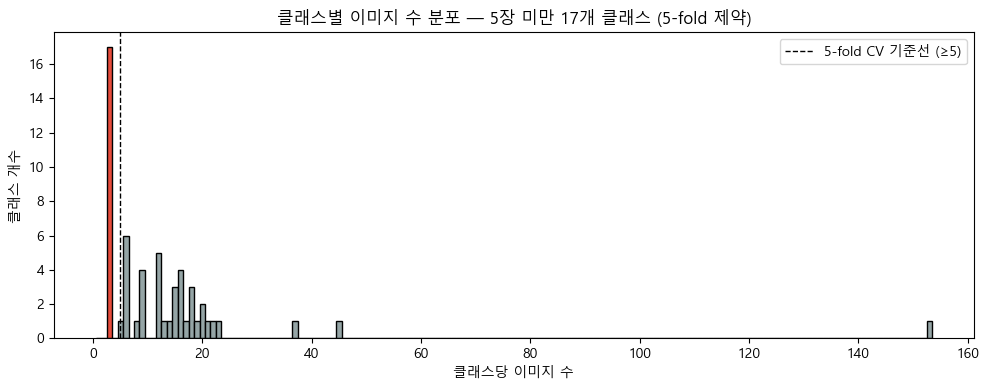

In [113]:
# ===== Cell 18-시각화: 클래스별 이미지 수 분포 (5장 미만 강조) =====
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(10, 4))
max_n = int(cls_img_counts.max())
bins = range(1, max_n + 2)
counts, edges, patches = ax.hist(cls_img_counts, bins=bins, edgecolor='black', align='left')

for i, p in enumerate(patches):
    p.set_facecolor('#e74c3c' if edges[i] < 5 else '#95a5a6')

ax.axvline(5, color='black', linestyle='--', linewidth=1, label='5-fold CV 기준선 (≥5)')
ax.set_xlabel('클래스당 이미지 수')
ax.set_ylabel('클래스 개수')
n_under5 = int((cls_img_counts < 5).sum())
ax.set_title(f'클래스별 이미지 수 분포 — 5장 미만 {n_under5}개 클래스 (5-fold 제약)')
ax.legend()
plt.tight_layout()
plt.show()